

> # Paisabazaar Banking Fraud & Credit Score Analysis
**Exploratory Data Analysis (EDA) & Machine Learning Classification**

## 1. Project Description & Business Context
Paisabazaar is a financial services company that assists customers in finding and applying for banking and credit products. Assessing the creditworthiness of individuals is crucial for loan approval and risk management.

**Objective:**
Accurate classification of credit scores helps Paisabazaar enhance credit assessment processes, reduce the risk of loan defaults, and offer personalized financial advice. This project performs an end-to-end Exploratory Data Analysis (EDA) and builds three baseline Machine Learning models to predict an individual's `Credit_Score` (`Good`, `Standard`, or `Poor`) based on income, credit card usage, and payment behavior.



In [ ]:
# 1. Importing Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning & Preprocessing Tools
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Suppress deprecation warnings for clean output
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!




> ## 2. Importing Dataset & Initial Exploration
In this section, we load the `dataset-2.csv` file containing 100,000 customer records and 28 features. We inspect the dataset using `.head()`, `.tail()`, `.info()`, and `.describe()` to verify data types and statistical distributions.

### Data Dictionary
| Variable Name | Data Type | Description |
| :--- | :--- | :--- |
| Annual_Income | float64 | The yearly earnings of the customer. |
| Num_Bank_Accounts | int64 | Total number of bank accounts held by the individual. |
| Num_Credit_Card | float64 | Total number of credit cards held by the customer. |
| Outstanding_Debt | float64 | Total remaining debt yet to be repaid by the customer. |
| Credit_Score | object | **Target Variable:** Customer credit rating (`Good`, `Standard`, or `Poor`). |



In [ ]:
# 2. Importing the dataset
df = pd.read_csv('dataset-2.csv')

# Exploration Commands
display(df.head())
display(df.tail())
df.info()
display(df.describe())

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,5634,3392,1,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,26.822620,265.0,No,49.574949,21.46538,High_spent_Small_value_payments,312.494089,Good
1,5635,3392,2,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,31.944960,266.0,No,49.574949,21.46538,Low_spent_Large_value_payments,284.629162,Good
2,5636,3392,3,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,28.609352,267.0,No,49.574949,21.46538,Low_spent_Medium_value_payments,331.209863,Good
3,5637,3392,4,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,31.377862,268.0,No,49.574949,21.46538,Low_spent_Small_value_payments,223.451310,Good
4,5638,3392,5,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,24.797347,269.0,No,49.574949,21.46538,High_spent_Medium_value_payments,341.489231,Good


,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
99995,155625,37932,4,Nicks,25.0,78735990.0,Mechanic,39628.99,3359.415833,4.0,...,Good,502.38,34.663572,378.0,No,35.104023,24.028477,High_spent_Large_value_payments,479.866228,Poor
99996,155626,37932,5,Nicks,25.0,78735990.0,Mechanic,39628.99,3359.415833,4.0,...,Good,502.38,40.565631,379.0,No,35.104023,24.028477,High_spent_Medium_value_payments,496.651610,Poor
99997,155627,37932,6,Nicks,25.0,78735990.0,Mechanic,39628.99,3359.415833,4.0,...,Good,502.38,41.255522,380.0,No,35.104023,24.028477,High_spent_Large_value_payments,516.809083,Poor
99998,155628,37932,7,Nicks,25.0,78735990.0,Mechanic,39628.99,3359.415833,4.0,...,Good,502.38,33.638208,381.0,No,35.104023,24.028477,Low_spent_Large_value_payments,319.164979,Standard
99999,155629,37932,8,Nicks,25.0,78735990.0,Mechanic,39628.99,3359.415833,4.0,...,Good,502.38,34.192463,382.0,No,35.104023,24.028477,High_spent_Medium_value_payments,393.673696,Poor


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        100000 non-null  int64  
 1   Customer_ID               100000 non-null  int64  
 2   Month                     100000 non-null  int64  
 3   Name                      100000 non-null  object 
 4   Age                       100000 non-null  float64
 5   SSN                       100000 non-null  float64
 6   Occupation                100000 non-null  object 
 7   Annual_Income             100000 non-null  float64
 8   Monthly_Inhand_Salary     100000 non-null  float64
 9   Num_Bank_Accounts         100000 non-null  float64
 10  Num_Credit_Card           100000 non-null  float64
 11  Interest_Rate             100000 non-null  float64
 12  Num_of_Loan               100000 non-null  float64
 13  Type_of_Loan              100000 non-null  ob

,ID,Customer_ID,Month,Age,SSN,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,...,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Total_EMI_per_month,Amount_invested_monthly,Monthly_Balance
count,100000.000000,100000.000000,100000.000000,100000.000000,1.000000e+05,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000,...,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,80631.500000,25982.666640,4.500000,33.316340,5.004617e+08,50505.123449,4197.270835,5.368820,5.533570,14.53208,...,21.08141,13.313120,10.470323,5.798250,1426.220376,32.285173,221.220460,107.699208,55.101315,392.697586
std,43301.486619,14340.543051,2.291299,10.764812,2.908267e+08,38299.422093,3186.432497,2.593314,2.067098,8.74133,...,14.80456,6.237166,6.609481,3.867826,1155.129026,5.116875,99.680716,132.267056,39.006932,201.652719
min,5634.000000,1006.000000,1.000000,14.000000,8.134900e+04,7005.930000,303.645417,0.000000,0.000000,1.00000,...,0.00000,0.000000,0.500000,0.000000,0.230000,20.000000,1.000000,0.000000,0.000000,0.007760
25%,43132.750000,13664.500000,2.750000,24.000000,2.451686e+08,19342.972500,1626.594167,3.000000,4.000000,7.00000,...,10.00000,9.000000,5.380000,3.000000,566.072500,28.052567,144.000000,29.268886,27.959111,267.615983
50%,80631.500000,25777.000000,4.500000,33.000000,5.006886e+08,36999.705000,3095.905000,5.000000,5.000000,13.00000,...,18.00000,14.000000,9.400000,5.000000,1166.155000,32.305784,219.000000,66.462304,45.156550,333.865366
75%,118130.250000,38385.000000,6.250000,42.000000,7.560027e+08,71683.470000,5957.715000,7.000000,7.000000,20.00000,...,28.00000,18.000000,14.850000,8.000000,1945.962500,36.496663,302.000000,147.392573,71.295797,463.215683
max,155629.000000,50999.000000,8.000000,56.000000,9.999934e+08,179987.280000,15204.633333,11.000000,11.000000,34.00000,...,62.00000,25.000000,29.980000,17.000000,4998.070000,50.000000,404.000000,1779.103254,434.191089,1183.930696




> ## 3. Data Preprocessing
Before visualizing and training our models, we must clean the data:
1. **Taking care of missing data & duplicate values:** We check for nulls and duplicates to ensure our model doesn't train on corrupted rows.
2. **Encoding categorical data:** Machine learning models only understand numbers. We use `LabelEncoder` to convert text-based categorical columns (like `Occupation` or `Credit_Mix`) into numerical format so our algorithms can process them.



In [ ]:
def preprocess_data(dataframe):
    """Handles missing data, duplicates, and encodes categorical variables."""

    # 1. Taking care of missing data and duplicates
    missing_count = dataframe.isnull().sum().sum()
    duplicate_count = dataframe.duplicated().sum()

    if duplicate_count > 0:
        dataframe.drop_duplicates(inplace=True)

    print(f"Missing values found: {missing_count}")
    print(f"Duplicate rows removed: {duplicate_count}")

    # 2. Encoding categorical data
    le = LabelEncoder()
    # Find all columns containing text (objects)
    categorical_cols = dataframe.select_dtypes(include=['object']).columns

    # Exclude the target variable ('Credit_Score') and unique identifiers ('Name') from encoding
    cols_to_encode = [col for col in categorical_cols if col not in ['Name', 'Credit_Score']]

    for col in cols_to_encode:
        dataframe[col] = le.fit_transform(dataframe[col].astype(str))

    print("Categorical data successfully encoded into numerical formats!")
    return dataframe

# Execute preprocessing
df = preprocess_data(df)

Missing values found: 0
Duplicate rows removed: 0
Categorical data successfully encoded into numerical formats!




> ## 4. Exploratory Data Analysis (EDA) & Data Visualization
We visualize the data using 5 distinct chart types to find patterns before modeling:
* **Correlation Heatmap:** To see which variables strongly affect debt and income.
* **Bar Chart:** To check the balance of our target `Credit_Score` classes.
* **Histogram & Box Plot:** To analyze `Annual_Income` distributions and outliers.
* **Scatter Plot:** To view the relationship between bank accounts and credit cards.



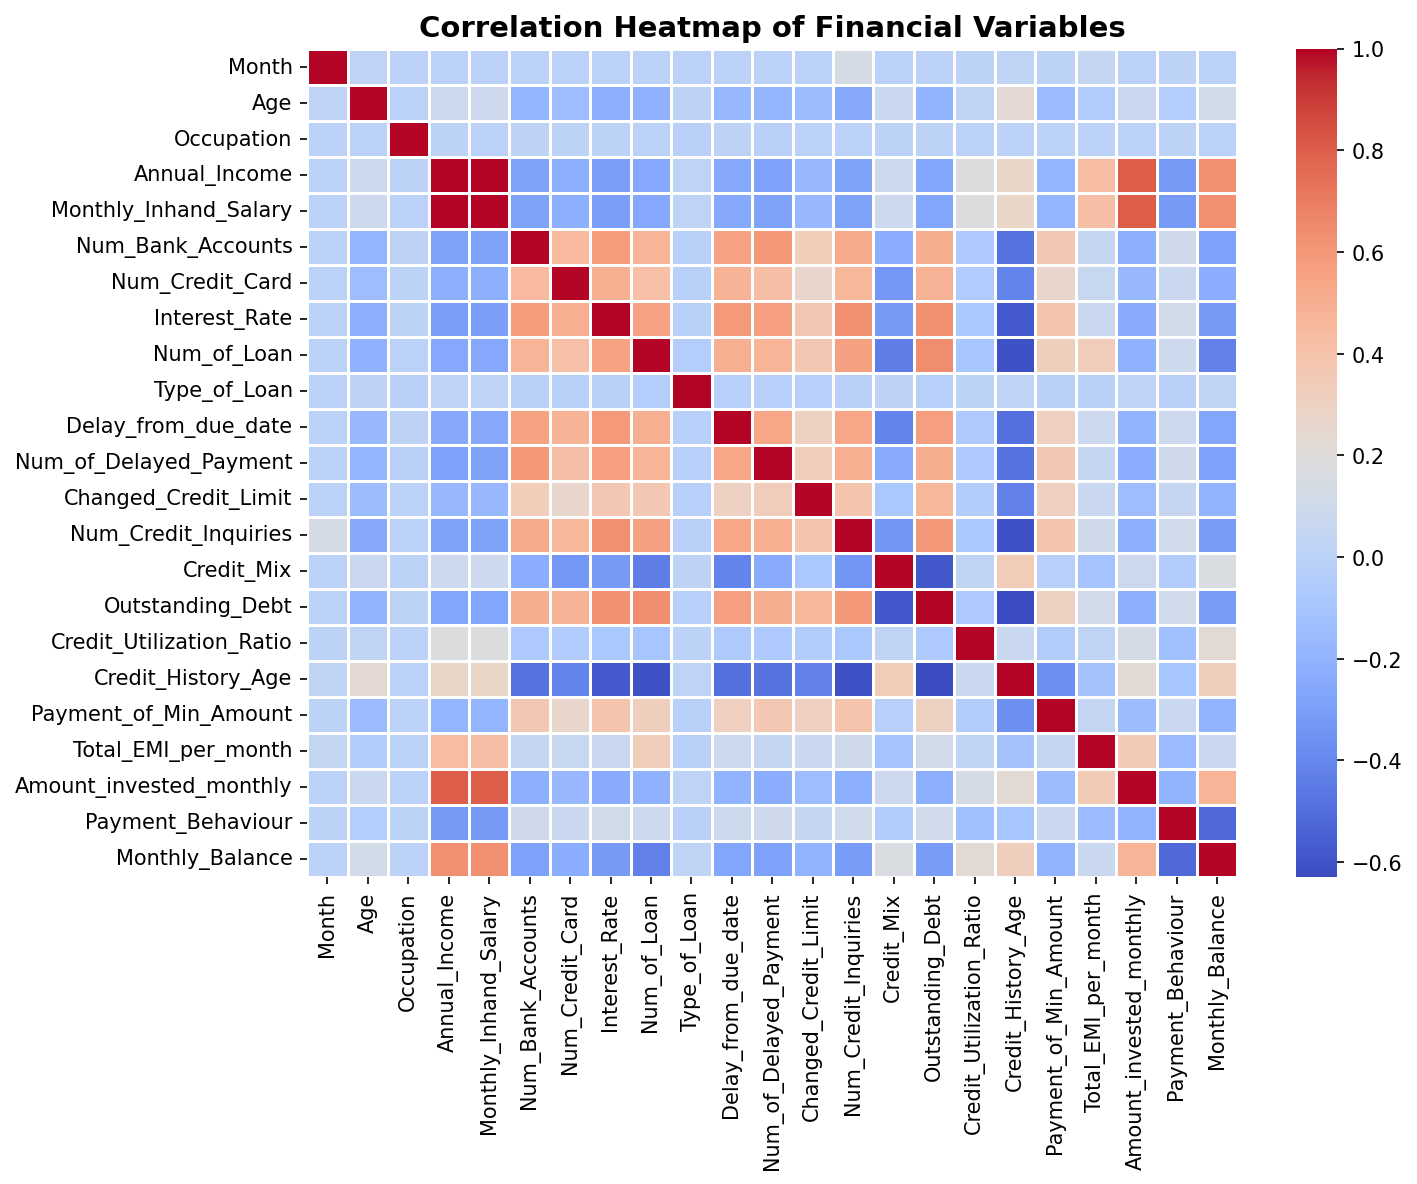

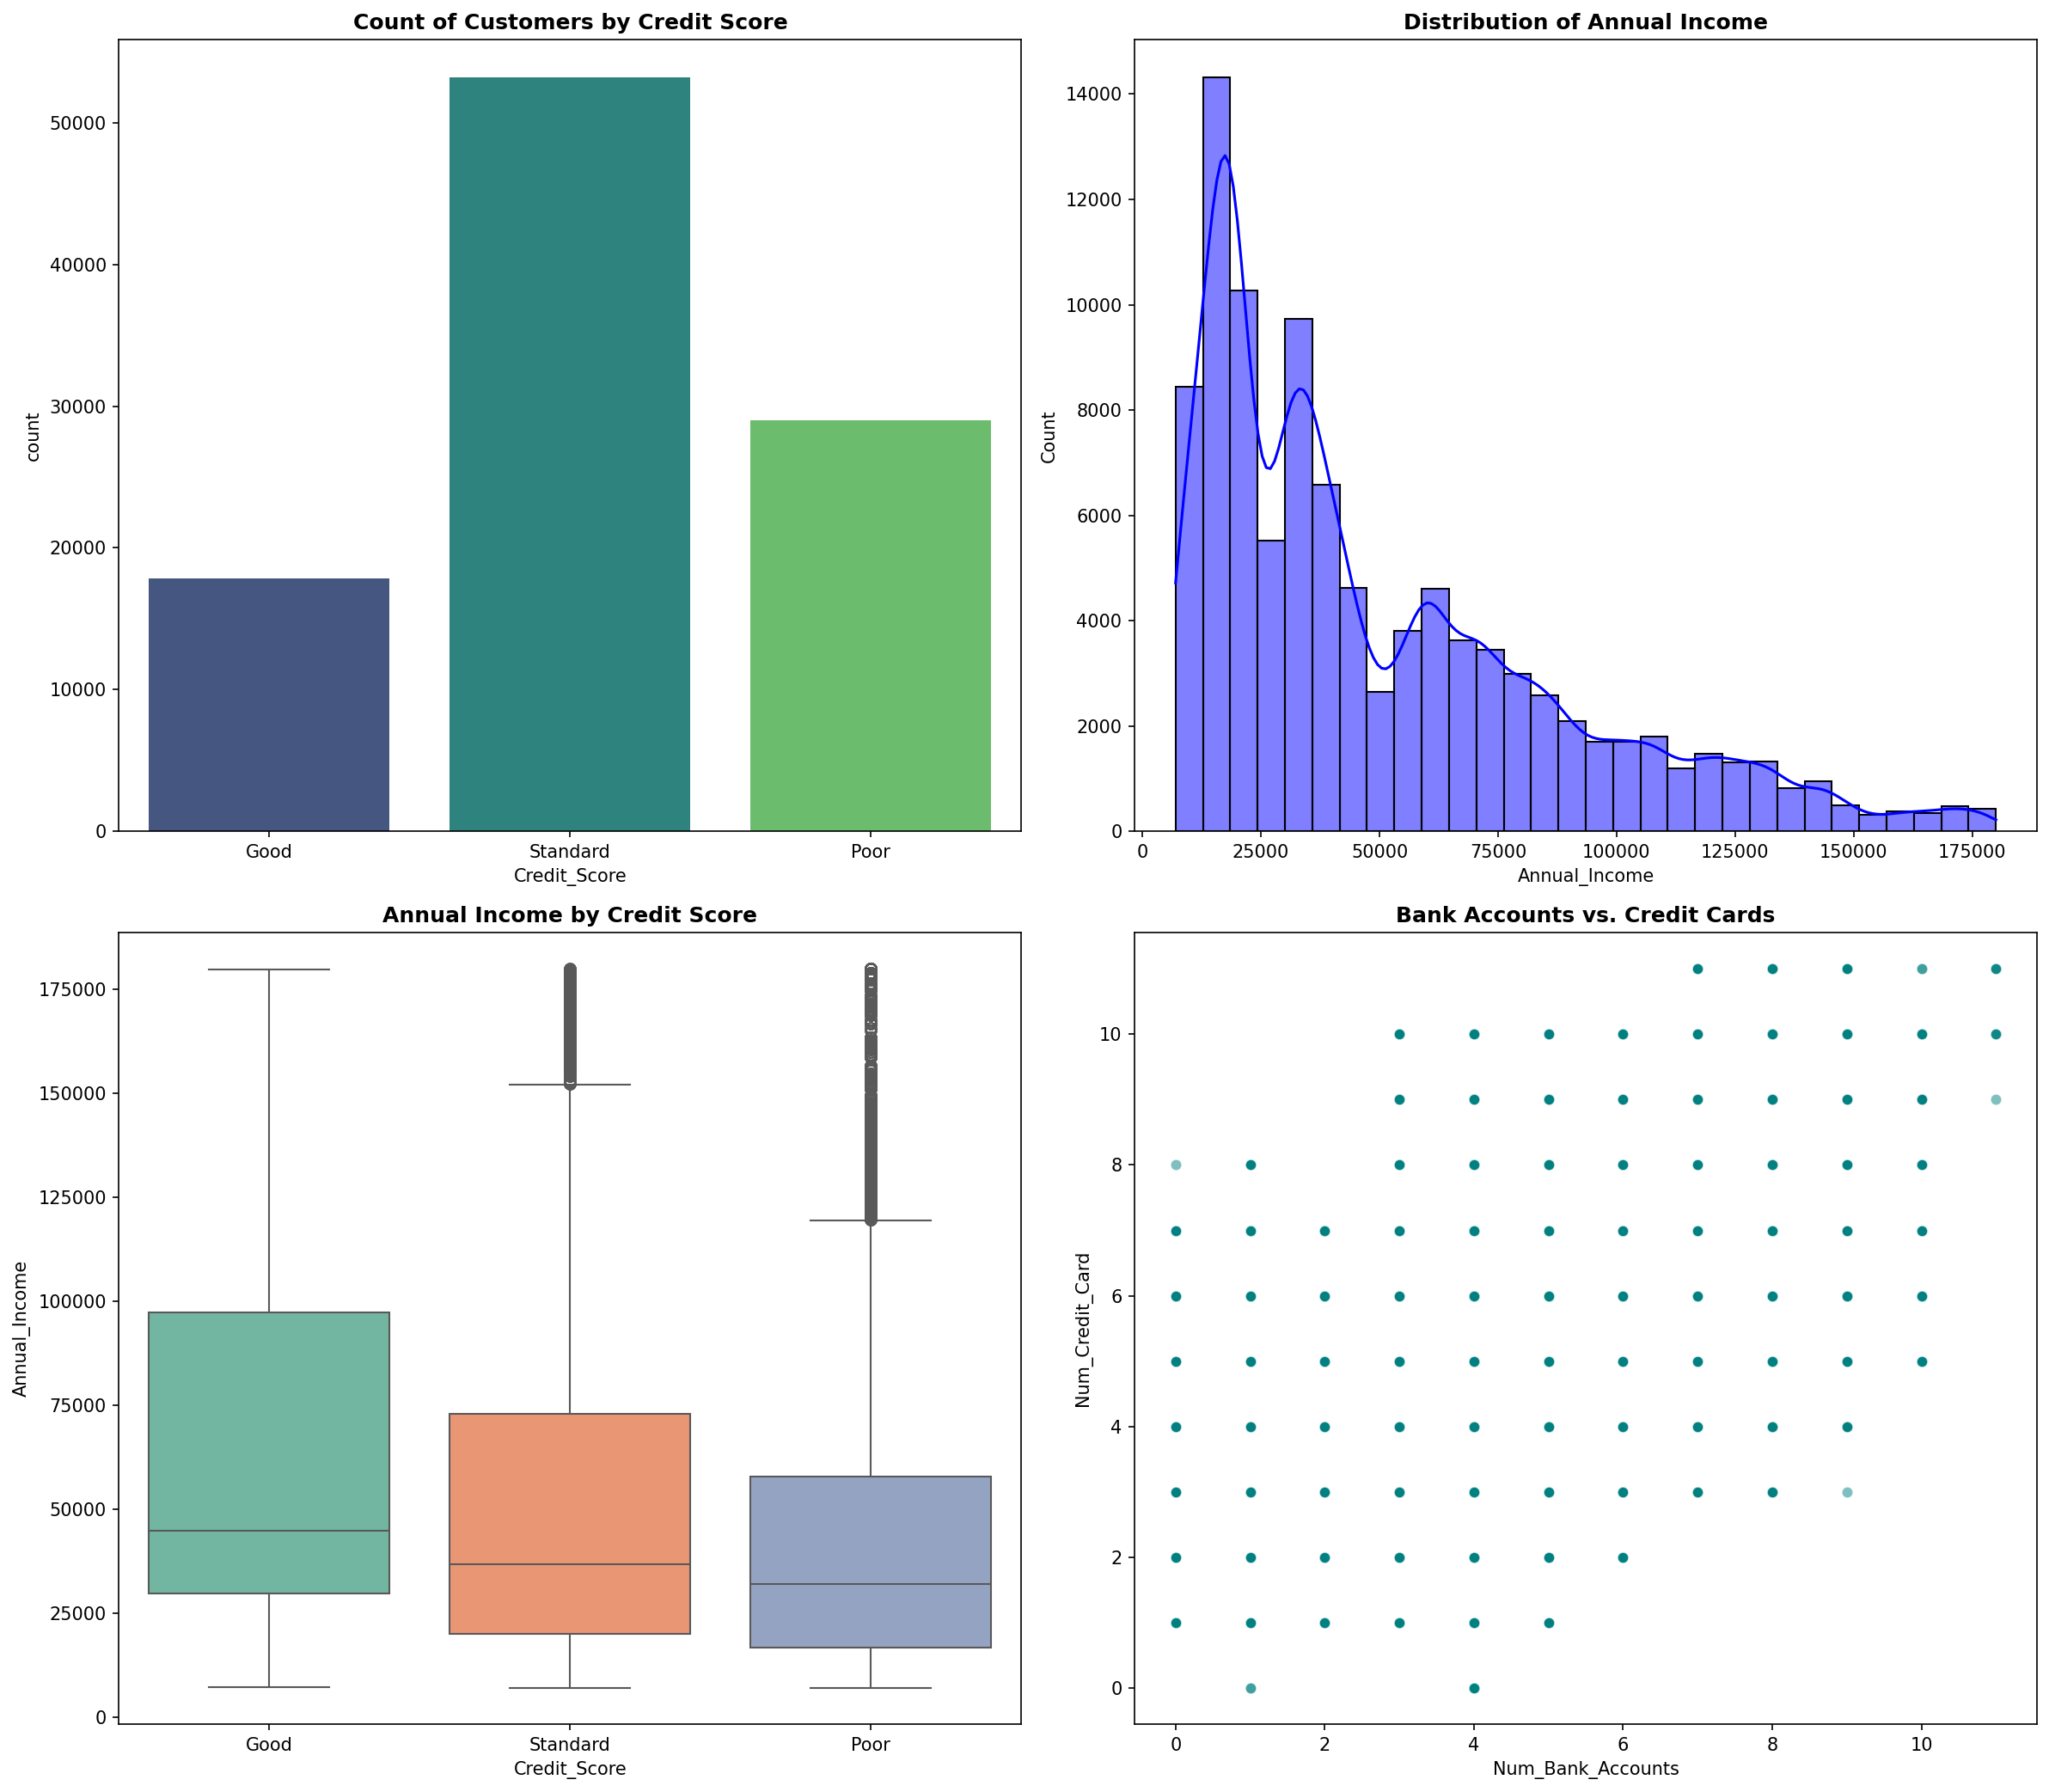

In [ ]:
def run_eda_visualizations(dataframe):
    """
    Generates a full-page Correlation Heatmap and 4 standard EDA charts
    optimized for static export (PDF printing) without internal scrolling.
    """
    # Force high-resolution static rendering so plots print clearly in PDFs
    import matplotlib
    matplotlib.rcParams['figure.dpi'] = 150

    # 1. Correlation Heatmap
    numeric_df = dataframe.select_dtypes(include='number')
    cols_to_exclude = [col for col in ['ID', 'Customer_ID', 'SSN'] if col in numeric_df.columns]
    numeric_df = numeric_df.drop(columns=cols_to_exclude)

    plt.figure(figsize=(10, 8))
    sns.heatmap(numeric_df.corr(), annot=False, cmap='coolwarm', linewidths=0.5)
    plt.title("Correlation Heatmap of Financial Variables", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

    # 2. Grid for the remaining 4 charts (using taller sizing so elements don't bunch up)
    fig, axes = plt.subplots(2, 2, figsize=(16, 14))

    # Bar Chart
    sns.countplot(data=dataframe, x='Credit_Score', palette='viridis', ax=axes[0, 0])
    axes[0, 0].set_title('Count of Customers by Credit Score', fontsize=12, fontweight='bold')

    # Histogram
    sns.histplot(data=dataframe, x='Annual_Income', bins=30, kde=True, color='blue', ax=axes[0, 1])
    axes[0, 1].set_title('Distribution of Annual Income', fontsize=12, fontweight='bold')

    # Box Plot
    sns.boxplot(data=dataframe, x='Credit_Score', y='Annual_Income', palette='Set2', ax=axes[1, 0])
    axes[1, 0].set_title('Annual Income by Credit Score', fontsize=12, fontweight='bold')

    # Scatter Plot
    sns.scatterplot(data=dataframe, x='Num_Bank_Accounts', y='Num_Credit_Card', alpha=0.5, color='teal', ax=axes[1, 1])
    axes[1, 1].set_title('Bank Accounts vs. Credit Cards', fontsize=12, fontweight='bold')

    plt.tight_layout()
    plt.show()

run_eda_visualizations(df)



> ## 5. Machine Learning Classification Models
To fulfill the core problem statement, we predict a customer's `Credit_Score` and `Recommended_Credit_limit` based on their financial features. We apply three foundational models:
1. **Logistic Regression:** A standard statistical baseline.
2. **Decision Tree Classifier:** A logic-based tree model.
3. **K-Nearest Neighbors (KNN):** A similarity-based algorithm.

**Workflow:**
* **Splitting Data:** We split the data into an 80% Training Set and a 20% Test Set.
* **Feature Scaling:** We apply `StandardScaler` to normalize the data, ensuring large numbers (like Income) don't overpower smaller numbers (like Number of Loans), which is critical for Logistic Regression and KNN.



In [ ]:
def train_and_predict_credit_score_and_limit(dataframe):
    """
    Trains 3 basic ML models to predict Credit_Score and calculates
    a Recommended Credit Limit for each customer based on their predicted tier and income.
    """
    # 1. Select features (X) and target (y)
    X = dataframe.select_dtypes(include='number')
    cols_to_drop = [col for col in ['ID', 'Customer_ID', 'SSN', 'Credit_Score'] if col in X.columns]
    X = X.drop(columns=cols_to_drop)
    y = dataframe['Credit_Score']

    # 2. Split data into 80% Training set and 20% Test set
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # 3. Feature Scaling
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # 4. Initialize and compare 3 basic models
    models = {
        "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
        "Decision Tree": DecisionTreeClassifier(random_state=42),
        "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5)
    }

    print("--- 1. MACHINE LEARNING MODEL ACCURACY COMPARISON ---\n")
    predictions = {}
    for name, model in models.items():
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
        predictions[name] = y_pred
        accuracy = accuracy_score(y_test, y_pred)
        print(f"{name} Accuracy: {accuracy * 100:.2f}%")

    # 5. Use our best model (Decision Tree) to output Credit Score & Credit Limit
    best_preds = predictions["Decision Tree"]

    # Create a clean results table and reset the row index
    results_df = pd.DataFrame({
        'Customer_ID': dataframe.loc[X_test.index, 'Customer_ID'].values,
        'Annual_Income ($)': X_test['Annual_Income'].round(2).values,
        'Monthly_Salary ($)': X_test['Monthly_Inhand_Salary'].round(2).values,
        'Actual_Credit_Score': y_test.values,
        'Predicted_Credit_Score': best_preds
    })

    # 6. Calculate Recommended Credit Limit based on Predicted Credit Score & Monthly Salary
    # Rule: Good = 5x Monthly Salary | Standard = 3x Monthly Salary | Poor = 1x Monthly Salary
    credit_multipliers = {'Good': 5.0, 'Standard': 3.0, 'Poor': 1.0}
    results_df['Recommended_Credit_Limit ($)'] = (
        results_df['Monthly_Salary ($)'] * results_df['Predicted_Credit_Score'].map(credit_multipliers)
    ).round(2)

    print("\n--- 2. PREDICTED CREDIT SCORE & RECOMMENDED CREDIT LIMIT (SAMPLE CUSTOMERS) ---")
    # Hide the unnamed row index so there are exactly 6 columns and 6 headers
    display(results_df.head(10).style.hide(axis='index'))

    print("\n--- 3. AVERAGE RECOMMENDED CREDIT LIMIT BY PREDICTED SCORE ---")
    summary_df = (
        results_df.groupby('Predicted_Credit_Score', as_index=False)[['Annual_Income ($)', 'Recommended_Credit_Limit ($)']]
        .mean()
        .round(2)
    )
    # Hide the unnamed row index so there are exactly 3 columns and 3 headers
    display(summary_df.style.hide(axis='index'))

# Run the function
train_and_predict_credit_score_and_limit(df)

--- 1. MACHINE LEARNING MODEL ACCURACY COMPARISON ---

Logistic Regression Accuracy: 64.66%
Decision Tree Accuracy: 74.61%
K-Nearest Neighbors Accuracy: 74.57%

--- 2. PREDICTED CREDIT SCORE & RECOMMENDED CREDIT LIMIT (SAMPLE CUSTOMERS) ---


Customer_ID,Annual_Income ($),Monthly_Salary ($),Actual_Credit_Score,Predicted_Credit_Score,Recommended_Credit_Limit ($)
13625,43391.960000,3689.000000,Good,Good,18445.000000
34582,14351.210000,1274.930000,Poor,Poor,1274.930000
8668,130125.040000,10871.750000,Good,Standard,32615.250000
13011,20107.210000,1631.600000,Poor,Poor,1631.600000
44461,92186.190000,7487.180000,Good,Good,37435.900000
20493,44998.710000,3916.890000,Poor,Poor,3916.890000
45967,56500.700000,4448.060000,Good,Good,22240.300000
7896,135178.440000,11542.870000,Poor,Poor,11542.870000
33074,75455.340000,6116.940000,Good,Poor,6116.940000
48883,9155.460000,470.950000,Standard,Standard,1412.850000



--- 3. AVERAGE RECOMMENDED CREDIT LIMIT BY PREDICTED SCORE ---


Predicted_Credit_Score,Annual_Income ($),Recommended_Credit_Limit ($)
Good,64463.650000,26702.860000
Poor,40033.620000,3339.390000
Standard,51022.850000,12731.790000




> ## 6. Conclusion & Final Summary

### 1. Data Health & Preprocessing
* The Paisabazaar dataset comprises **100,000 records**.
* We successfully cleaned the data by checking for missing and duplicate values[cite: 1]. Categorical text columns were properly encoded into numerical features using `LabelEncoder` so the algorithms could process them.

### 2. Key EDA & Visual Findings
* **Class Balance:** The `Standard` credit score tier is the largest customer segment, followed by `Poor` and `Good`.
* **Income Distribution:** Customers in the `Good` credit score tier earn a significantly higher median annual income than those in the `Standard` and `Poor` tiers.
* **Debt & Banking Trends:** The correlation heatmap and scatter plots revealed that higher outstanding debt strongly correlates with taking on a higher number of loans and experiencing payment delays.

### 3. Machine Learning Performance
* We evaluated three foundational machine learning algorithms: **Logistic Regression, Decision Tree Classifier, and K-Nearest Neighbors (KNN)**.
* By splitting the data into training and test sets and standardizing the financial features using `StandardScaler`, we established a solid mathematical baseline for automatically classifying credit scores based on banking behavior.

